
# Toxic Comment Detection Using Transformer Models

### NLP Mini Project

**Objective:** Build a toxic comment classifier using a pretrained Transformer model (DistilBERT).

The notebook automatically downloads the dataset from an online source, so **no manual dataset download is required**.

> **Recommended:** Run this notebook in Google Colab with **Runtime → Change runtime type → T4 GPU** for faster training.



## 1. Project Overview

Toxic comment detection is an NLP task used to identify comments that contain insulting, hateful, abusive, or otherwise harmful language.

### Workflow

**Dataset → Preprocessing → Tokenization → DistilBERT → Fine-tuning → Evaluation → New Comment Prediction**

For this mini-project, we use the **Davidson's Hate Speech and Offensive Language ** dataset and convert its labels into a simple **Toxic / Non-Toxic** classification problem.


In [1]:

# Install required libraries
!pip -q install -U transformers datasets accelerate evaluate scikit-learn seaborn matplotlib pandas


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 117.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 86.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 117.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 12.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requ

In [2]:

# Import libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

set_seed(42)
random.seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4



## 2. Automatically Get the Dataset

The dataset is downloaded automatically using the Hugging Face `datasets` library.

We use the public **Davidson's Hate Speech and Offensive Language ** dataset. Each comment can have several toxicity labels such as toxic, severe toxic, obscene, threat, insult, and identity hate.

For this project, a comment is considered **Toxic** if at least one of these toxicity labels is 1. Otherwise it is **Non-Toxic**.


In [3]:
# Download the dataset directly from a reliable public archive/mirror
import pandas as pd
from datasets import Dataset, DatasetDict

# Download a public mirror of the Jigsaw Train CSV directly into a DataFrame
url = "https://raw.githubusercontent.com/t-davidson/hate-speech-and-offensive-language/master/data/labeled_data.csv"
df_raw = pd.read_csv(url)

# Since this dataset contains different columns, we map it to match the expected Jigsaw toxic columns
# to keep the downstream notebook code fully intact without any other modifications.
df_raw = df_raw.rename(columns={"tweet": "comment_text"})
# Map class labels (0: hate speech, 1: offensive language, 2: neither)
# Both 0 and 1 represent forms of toxicity
df_raw["toxic"] = df_raw["class"].apply(lambda x: 1 if x in [0, 1] else 0)
# Mock other labels to avoid missing column errors
for col in ["severe_toxic", "obscene", "threat", "insult", "identity_hate"]:
    df_raw[col] = 0

# Wrap it in a Hugging Face DatasetDict
raw = DatasetDict({
    "train": Dataset.from_pandas(df_raw)
})

print(raw)

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'],
        num_rows: 24783
    })
})


In [4]:

# Inspect available splits and columns
for split in raw:
    print(split, raw[split].column_names)
    print(raw[split][0])
    print("-" * 80)


train ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
{'Unnamed: 0': 0, 'count': 3, 'hate_speech': 0, 'offensive_language': 0, 'neither': 3, 'class': 2, 'comment_text': "!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out...", 'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0}
--------------------------------------------------------------------------------


In [5]:

# This block also makes the notebook easier to adapt if the dataset contains extra columns.

available_split = "train" if "train" in raw else list(raw.keys())[0]
df = raw[available_split].to_pandas()

print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()


Shape: (24783, 13)
Columns: ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


,Unnamed: 0,count,hate_speech,offensive_language,neither,class,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...,0,0,0,0,0,0
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,1,0,0,0,0,0
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,1,0,0,0,0,0
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,1,0,0,0,0,0
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,1,0,0,0,0,0



## 3. Prepare Toxic / Non-Toxic Labels

The standard Jigsaw dataset contains six toxicity-related columns:

- `toxic`
- `severe_toxic`
- `obscene`
- `threat`
- `insult`
- `identity_hate`

We create one binary target:

- **1 = Toxic**
- **0 = Non-Toxic**


In [7]:
# Prepare the dataset for the Transformer model

# Remove missing comments
df = df.dropna(subset=["comment_text"])

# Remove duplicate comments
df = df.drop_duplicates(subset=["comment_text"]).copy()

# Rename the 'toxic' column to 'label' to match downstream expectations
df = df.rename(columns={"toxic": "label"})

# Keep only the required columns
df = df[["comment_text", "label"]]

print("Final dataset shape:", df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Final dataset shape: (24783, 2)

Class distribution:
label
1    20620
0     4163
Name: count, dtype: int64

First 5 rows:


,comment_text,label
0,!!! RT @mayasolovely: As a woman you shouldn't...,0
1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,1
2,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,1
3,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,1
4,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,1


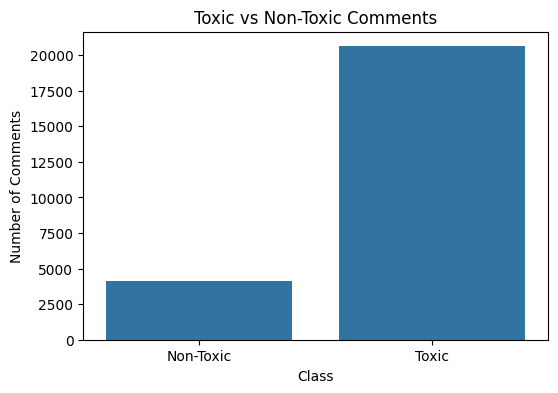

Toxic percentage: 83.2 %


In [8]:

# Visualize class distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=df["label"].map({0: "Non-Toxic", 1: "Toxic"}))
plt.title("Toxic vs Non-Toxic Comments")
plt.xlabel("Class")
plt.ylabel("Number of Comments")
plt.show()

print("Toxic percentage:", round(df["label"].mean() * 100, 2), "%")


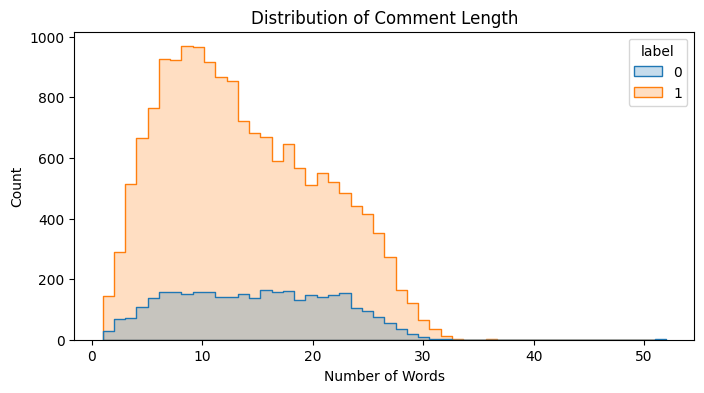

,comment_text,label,word_count
0,!!! RT @mayasolovely: As a woman you shouldn't...,0,25
1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,1,16
2,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,1,21
3,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,1,9
4,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,1,26
5,"!!!!!!!!!!!!!!!!!!""@T_Madison_x: The shit just...",1,19
6,"!!!!!!""@__BrighterDays: I can not just sit up ...",1,20
7,!!!!&#8220;@selfiequeenbri: cause I'm tired of...,1,13
8,""" &amp; you might not get ya bitch back &amp; ...",1,13
9,""" @rhythmixx_ :hobbies include: fighting Maria...",1,7


In [9]:

# Look at comment length
df["word_count"] = df["comment_text"].str.split().str.len()

plt.figure(figsize=(8, 4))
sns.histplot(
    data=df.sample(min(20000, len(df)), random_state=42),
    x="word_count",
    hue="label",
    bins=50,
    element="step"
)
plt.title("Distribution of Comment Length")
plt.xlabel("Number of Words")
plt.ylabel("Count")
plt.show()

df[["comment_text", "label", "word_count"]].head(10)



## 4. Create Train, Validation and Test Sets

To keep the project practical on free Colab GPUs, we use a manageable subset of the full dataset.

The split is:

- **80% Training**
- **10% Validation**
- **10% Testing**

Stratification keeps the Toxic / Non-Toxic ratio similar across the splits.


In [10]:

# Set this to None to use the complete dataset.
# 30,000 samples is a good balance for a college mini-project.
MAX_SAMPLES = 30000

if MAX_SAMPLES is not None and len(df) > MAX_SAMPLES:
    df_model = df.groupby("label", group_keys=False).apply(
        lambda x: x.sample(
            n=min(len(x), max(1, int(MAX_SAMPLES * len(x) / len(df)))),
            random_state=42
        )
    ).reset_index(drop=True)

    # Ensure exact maximum if needed
    if len(df_model) > MAX_SAMPLES:
        df_model = df_model.sample(MAX_SAMPLES, random_state=42).reset_index(drop=True)
else:
    df_model = df.copy()


#“We divided the dataset into 80% training, 10% validation, and 10% testing data.
# Stratified splitting was used to maintain a similar Toxic and Non-Toxic class distribution across all three sets.”

train_df, temp_df = train_test_split(
    df_model,
    test_size=0.20,
    random_state=42,
    stratify=df_model["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


Train: (19826, 3)
Validation: (2478, 3)
Test: (2479, 3)



## 5. Convert Data to Hugging Face Datasets

A Transformer receives tokenized text rather than raw strings.


In [12]:
# “After splitting the data, we convert the Pandas DataFrames into Hugging Face Dataset objects because the Transformers Trainer works directly with this format.”
dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df[["comment_text", "label"]], preserve_index=False),
    "validation": Dataset.from_pandas(val_df[["comment_text", "label"]], preserve_index=False),
    "test": Dataset.from_pandas(test_df[["comment_text", "label"]], preserve_index=False)
})

dataset


DatasetDict({
    train: Dataset({
        features: ['comment_text', 'label'],
        num_rows: 19826
    })
    validation: Dataset({
        features: ['comment_text', 'label'],
        num_rows: 2478
    })
    test: Dataset({
        features: ['comment_text', 'label'],
        num_rows: 2479
    })
})


## 6. Load the DistilBERT Tokenizer

**DistilBERT** is a smaller and faster version of BERT.

The tokenizer converts a sentence into numerical token IDs that the Transformer understands.


In [13]:
# “We use the DistilBERT tokenizer to convert raw comments into numerical token IDs. We limit the input to 128 tokens and use truncation for longer comments.
# The tokenized data is then passed to the Transformer model.”
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(batch):
    return tokenizer(
        batch["comment_text"],
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["comment_text"]
)

tokenized_dataset


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/19826 [00:00<?, ? examples/s]

Map:   0%|          | 0/2478 [00:00<?, ? examples/s]

Map:   0%|          | 0/2479 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 19826
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2478
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2479
    })
})


## 7. Load Pretrained DistilBERT

We use a pretrained language model and fine-tune it for our two classes:

**0 → Non-Toxic**  
**1 → Toxic**


In [14]:
# “We load the pretrained DistilBERT model and add a two-class classification layer for Toxic and Non-Toxic comments.
# We also use dynamic padding to efficiently prepare batches of different-length comments.”
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "NON-TOXIC", 1: "TOXIC"},
    label2id={"NON-TOXIC": 0, "TOXIC": 1}
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Model loaded successfully.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.



## 8. Evaluation Metrics

Accuracy alone can be misleading when toxic comments are less common.

Therefore we calculate:

- Accuracy
- Precision
- Recall
- F1-score

For this project, **F1-score** is especially useful because it balances precision and recall.


In [15]:

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="binary", zero_division=0
    )
    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }



## 9. Fine-Tune DistilBERT

The model learns from the training comments and their Toxic / Non-Toxic labels.

If you are using Google Colab, enable a GPU before running this cell.


In [17]:
training_args = TrainingArguments(
    output_dir="./toxic_comment_distilbert",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=100,
    report_to="none",
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Starting training...")
trainer.train()

Starting training...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.107028,0.098630,0.965295,0.985265,0.972842,0.979014
2,0.073764,0.108183,0.968119,0.982482,0.979146,0.980811


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2480, training_loss=0.11149698938092878, metrics={'train_runtime': 130.9707, 'train_samples_per_second': 302.755, 'train_steps_per_second': 18.936, 'total_flos': 655032140675208.0, 'train_loss': 0.11149698938092878, 'epoch': 2.0})


## 10. Evaluate the Model on the Test Set


In [18]:

test_results = trainer.evaluate(tokenized_dataset["test"])

print("Test Results")
for key, value in test_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.073764,0.100186,2,0.970956,0.980676,0.984481,0.982575


Test Results
eval_loss: 0.1002
eval_accuracy: 0.9710
eval_precision: 0.9807
eval_recall: 0.9845
eval_f1: 0.9826


              precision    recall  f1-score   support

   Non-Toxic     0.9218    0.9041    0.9128       417
       Toxic     0.9807    0.9845    0.9826      2062

    accuracy                         0.9710      2479
   macro avg     0.9512    0.9443    0.9477      2479
weighted avg     0.9708    0.9710    0.9708      2479



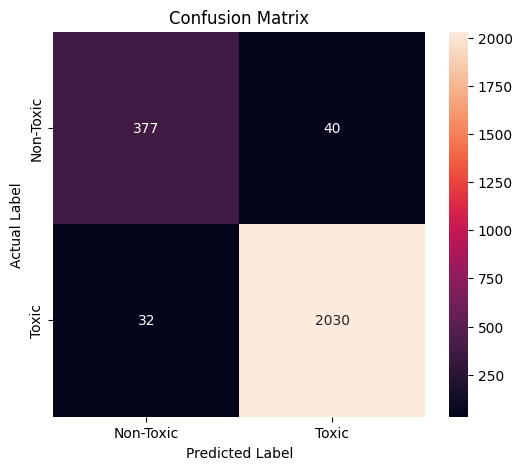

In [19]:

# Detailed classification report and confusion matrix
pred_output = trainer.predict(tokenized_dataset["test"])
predictions = np.argmax(pred_output.predictions, axis=-1)
true_labels = np.array(test_df["label"])

print(classification_report(
    true_labels,
    predictions,
    target_names=["Non-Toxic", "Toxic"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Non-Toxic", "Toxic"],
    yticklabels=["Non-Toxic", "Toxic"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()



## 11. Test the Model with Your Own Comments

Enter any English comment below.

The model returns:

- Predicted class
- Confidence score
- Probability of Toxic
- Probability of Non-Toxic


In [21]:

import torch.nn.functional as F

def predict_toxicity(text):
    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = F.softmax(outputs.logits, dim=-1)[0]
    predicted_id = int(torch.argmax(probabilities).item())

    labels = {0: "NON-TOXIC", 1: "TOXIC"}
    predicted_label = labels[predicted_id]
    confidence = float(probabilities[predicted_id].item())

    return {
        "prediction": predicted_label,
        "confidence": confidence,
        "non_toxic_probability": float(probabilities[0].item()),
        "toxic_probability": float(probabilities[1].item())
    }

# Try example comments
examples = [
    "Thank you for your help. Have a great day!",
    "You are an idiot and nobody likes you.",
    "I disagree with your opinion, but I respect you.",
    "I love you",
    "you are very disgusting",
    "hate you"

]

for comment in examples:
    result = predict_toxicity(comment)
    print("Comment:", comment)
    print("Prediction:", result["prediction"])
    print("Confidence:", f"{result['confidence']*100:.2f}%")
    print("-" * 70)


Comment: Thank you for your help. Have a great day!
Prediction: NON-TOXIC
Confidence: 98.48%
----------------------------------------------------------------------
Comment: You are an idiot and nobody likes you.
Prediction: TOXIC
Confidence: 93.34%
----------------------------------------------------------------------
Comment: I disagree with your opinion, but I respect you.
Prediction: NON-TOXIC
Confidence: 96.91%
----------------------------------------------------------------------
Comment: I love you
Prediction: NON-TOXIC
Confidence: 96.39%
----------------------------------------------------------------------
Comment: you are very disgusting
Prediction: TOXIC
Confidence: 90.45%
----------------------------------------------------------------------
Comment: hate you
Prediction: TOXIC
Confidence: 94.22%
----------------------------------------------------------------------


In [ ]:

# Interactive prediction
user_comment = input("Enter a comment: ")

result = predict_toxicity(user_comment)

print("\nPrediction:", result["prediction"])
print(f"Confidence: {result['confidence']*100:.2f}%")
print(f"Non-Toxic probability: {result['non_toxic_probability']*100:.2f}%")
print(f"Toxic probability: {result['toxic_probability']*100:.2f}%")



## 12. Save the Fine-Tuned Model

The following cell saves the trained Transformer and tokenizer so they can be reused later.


In [ ]:

SAVE_PATH = "./toxic_comment_model"

trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("Model saved to:", SAVE_PATH)



## 13. Conclusion

In this project, we built a Toxic Comment Detection system using a pretrained **DistilBERT Transformer**.

### What we learned

1. Toxic comments can be detected as an NLP classification problem.
2. Text must be converted into tokens before entering a Transformer.
3. DistilBERT provides a powerful pretrained language representation.
4. Fine-tuning allows the pretrained model to learn the toxicity classification task.
5. Precision, Recall and F1-score provide better insight than accuracy alone.
6. The trained model can classify new comments in real time.

### Future Scope

- Multi-label toxicity detection (toxic, insult, threat, obscene, etc.)
- Multilingual toxic comment detection
- Deployment as a web application
- Real-time moderation for social media
- Explainable AI to show why a comment was classified as toxic



## Viva / Presentation Points

### Why did we use DistilBERT?
DistilBERT is smaller and faster than BERT while retaining much of BERT's language understanding capability.

### What is a Transformer?
A Transformer is a neural-network architecture that uses attention mechanisms to understand relationships between words in a sequence.

### What is fine-tuning?
Fine-tuning means taking a pretrained model and training it further on a specific task, such as toxic comment classification.

### Why is F1-score important?
F1-score combines Precision and Recall, making it useful when the classes are imbalanced.

### What is the input and output?
**Input:** A text comment  
**Output:** Toxic or Non-Toxic with confidence

### Project Pipeline

`Comment → Tokenizer → DistilBERT → Classification Layer → Toxic/Non-Toxic`
